# Bab 9 — Modeling Probabilities and Nonlinearities: Activation Functions

**Acuan:** Trask, *Grokking Deep Learning*, Bab 9, hlm. 161–175. Implementasi dan data tiga kelas di sini ditulis mandiri; contoh sintetis tidak mewakili hasil MNIST buku.

**Tujuan belajar:** membandingkan ReLU, sigmoid, dan tanh; menghitung softmax yang stabil; serta menurunkan dan memeriksa gradien jaringan klasifikasi multi-kelas.

## 1. Hidden activation dan turunannya

Aktivasi mengubah weighted sum sebelum diteruskan ke layer berikutnya. **Sigmoid** memetakan nilai ke $(0,1)$, tetapi turunannya $a(1-a)$ mendekati nol di ekor. **Tanh** memetakan ke $(-1,1)$ dengan turunan $1-a^2$ dan output berpusat di nol. **ReLU** memetakan nilai negatif ke nol; gradiennya nol saat input negatif dan tidak terdefinisi tepat di nol (implementasi biasanya memilih salah satu subgradien). Aktivasi membantu jaringan mewakili hubungan nonlinier, namun tidak ada fungsi yang selalu terbaik.

Penting membedakan **aktivasi hidden** dari **aktivasi output**: sigmoid sering dipakai untuk probabilitas satu kelas biner, sedangkan softmax untuk kelas yang saling eksklusif.

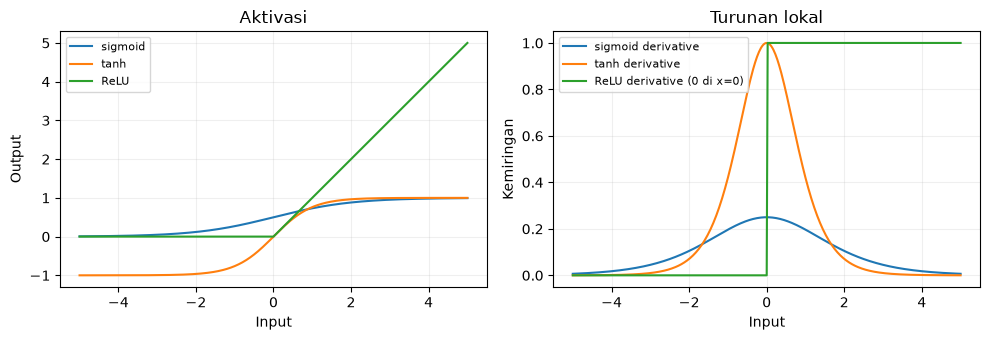

In [1]:
import numpy as np
import matplotlib.pyplot as plt

grid = np.linspace(-5, 5, 401)
sigmoid_curve = 1 / (1 + np.exp(-grid))
tanh_curve = np.tanh(grid)
relu_curve = np.maximum(0, grid)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, values in [('sigmoid', sigmoid_curve), ('tanh', tanh_curve), ('ReLU', relu_curve)]:
    axes[0].plot(grid, values, label=label)
axes[1].plot(grid, sigmoid_curve*(1-sigmoid_curve), label='sigmoid derivative')
axes[1].plot(grid, 1-tanh_curve**2, label='tanh derivative')
axes[1].plot(grid, (grid>0).astype(float), label='ReLU derivative (0 di x=0)')
axes[0].set(title='Aktivasi', xlabel='Input', ylabel='Output')
axes[1].set(title='Turunan lokal', xlabel='Input', ylabel='Kemiringan')
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 2. Softmax dari logits menjadi distribusi kelas

Untuk skor mentah (*logits*) $z_c$, softmax menghitung $p_c=e^{z_c}/\sum_j e^{z_j}$. Hasilnya positif dan berjumlah 1 untuk tiap contoh. Mengurangi maksimum logit sebelum eksponensial **tidak mengubah probabilitas** karena faktor pengali yang sama saling membatalkan, tetapi mencegah overflow. Probabilitas softmax adalah keluaran model bersyarat pada parameter dan data; ia tidak otomatis terkalibrasi dengan frekuensi kejadian di dunia nyata.

In [2]:
def softmax(logits):
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / exp_values.sum(axis=1, keepdims=True)

example = np.array([[2., 1., -1.], [1000., 999., 998.]])
probabilities = softmax(example)
print(probabilities.round(4))
print('Jumlah per baris:', probabilities.sum(axis=1))
assert np.allclose(probabilities.sum(axis=1), 1)
assert np.allclose(softmax(example + 100), probabilities)

[[0.7054 0.2595 0.0351]
 [0.6652 0.2447 0.09  ]]
Jumlah per baris: [1. 1.]


## 3. Cross-entropy dan sinyal gradien output

Untuk label satu-hot $Y$ dan probabilitas $P$, cross-entropy rata-rata adalah $L=-\frac1m\sum_{i,c}Y_{ic}\log P_{ic}$. Gabungan softmax dan cross-entropy memberi turunan logit sederhana: $dZ_2=(P-Y)/m$. Gradien hidden tetap mengikuti chain rule, termasuk turunan aktivasi. Kita memeriksa satu elemen gradien dengan beda hingga sebelum training. Seluruh data di bawah **sintetis** dan sengaja mudah dipisahkan; skor tinggi bukan bukti performa pada data riil.

In [3]:
rng = np.random.default_rng(19)
centers = np.array([[-1.4,-1.0], [1.4,-1.0], [0.,1.3]])
X = np.vstack([rng.normal(center, .35, size=(90, 2)) for center in centers])
labels = np.repeat(np.arange(3), 90)
order = rng.permutation(len(X))
train_ids, val_ids = order[:210], order[210:]
X_train, y_train = X[train_ids], labels[train_ids]
X_val, y_val = X[val_ids], labels[val_ids]

W1 = rng.normal(0, .25, size=(2, 8)); b1 = np.zeros((1, 8))
W2 = rng.normal(0, .25, size=(8, 3)); b2 = np.zeros((1, 3))

def forward(X_batch, W1, b1, W2, b2):
    h = np.tanh(X_batch @ W1 + b1)
    p = softmax(h @ W2 + b2)
    return h, p

def cross_entropy(p, y):
    return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1))))

def grads(X_batch, y, W1, b1, W2, b2):
    h, p = forward(X_batch, W1, b1, W2, b2)
    dz2 = p.copy()
    dz2[np.arange(len(y)), y] -= 1
    dz2 /= len(y)
    dW2 = h.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    dz1 = (dz2 @ W2.T) * (1 - h**2)
    dW1 = X_batch.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return dW1, db1, dW2, db2

dW1, _, _, _ = grads(X_train, y_train, W1, b1, W2, b2)
epsilon = 1e-5
plus, minus = W1.copy(), W1.copy()
plus[0, 0] += epsilon; minus[0, 0] -= epsilon
numeric = (cross_entropy(forward(X_train, plus, b1, W2, b2)[1], y_train)
           - cross_entropy(forward(X_train, minus, b1, W2, b2)[1], y_train)) / (2*epsilon)
print('Gradien W1[0,0] analitik/numerik:', round(dW1[0,0], 7), round(numeric, 7))
assert np.isclose(dW1[0,0], numeric, atol=1e-6)

Gradien W1[0,0] analitik/numerik: -0.0753726 -0.0753726


## 4. Training dan evaluasi terpisah

Optimasi berikut memakai full-batch gradient descent untuk menjaga perhitungan mudah diikuti. Validation set tidak ikut pembaruan bobot. Kurva validation membantu melihat apakah peningkatan training berlanjut ke contoh yang tidak dilatih; walaupun kedua kurva terlihat baik pada data sintetis, itu tidak menjamin generalisasi ke distribusi berbeda.

Cross-entropy awal/akhir training: 1.293 0.004
Akurasi validation: 1.0


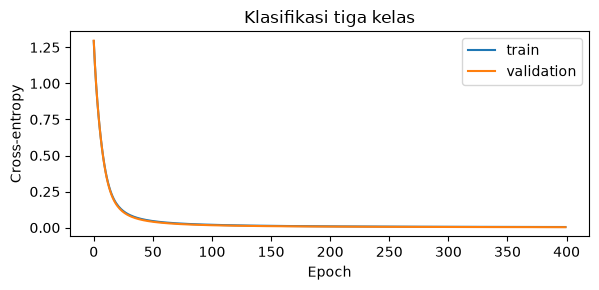

In [4]:
history = {'train': [], 'val': []}
for epoch in range(400):
    train_p = forward(X_train, W1, b1, W2, b2)[1]
    val_p = forward(X_val, W1, b1, W2, b2)[1]
    history['train'].append(cross_entropy(train_p, y_train))
    history['val'].append(cross_entropy(val_p, y_val))
    gW1, gb1, gW2, gb2 = grads(X_train, y_train, W1, b1, W2, b2)
    W1 -= .25*gW1; b1 -= .25*gb1
    W2 -= .25*gW2; b2 -= .25*gb2

val_p = forward(X_val, W1, b1, W2, b2)[1]
val_acc = np.mean(val_p.argmax(axis=1) == y_val)
print('Cross-entropy awal/akhir training:', round(history['train'][0], 3), round(history['train'][-1], 3))
print('Akurasi validation:', round(float(val_acc), 3))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history['train'], label='train'); ax.plot(history['val'], label='validation')
ax.set(xlabel='Epoch', ylabel='Cross-entropy', title='Klasifikasi tiga kelas')
ax.legend(); plt.tight_layout(); plt.show()
assert val_acc > .9

### Ringkasan dan refleksi

- Hidden activation menentukan bentuk representasi sekaligus jalur gradien.
- Sigmoid/tanh bisa jenuh pada input ekstrem; ReLU bisa mati pada sisi negatif.
- Softmax menormalkan logits antar-kelas eksklusif; implementasi stabil mengurangi logit maksimum.
- Softmax + cross-entropy menyederhanakan delta output menjadi $(P-Y)/m$, sedangkan turunan hidden tetap diperlukan.
- Probabilitas model dan akurasi pada data sintetis tidak otomatis valid untuk data dunia nyata.